In [1]:
from pathlib import Path

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_and_show(stem):
    """Save each open figure as PNG and vector PDF, then display it."""
    for index, number in enumerate(plt.get_fignums(), start=1):
        fig = plt.figure(number)
        suffix = f"_{index}" if len(plt.get_fignums()) > 1 else ""
        fig.savefig(FIGURES_DIR / f"{stem}{suffix}.png", dpi=180, bbox_inches="tight")
        fig.savefig(FIGURES_DIR / f"{stem}{suffix}.pdf", bbox_inches="tight")
    plt.show()
    plt.close("all")


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

In [3]:
# Paths

DATA_DIR = Path("../data/blogfeedback")
DATA_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = DATA_DIR / "blogfeedback.zip"

DATA_URL = (
    "https://archive.ics.uci.edu/static/public/304/blogfeedback.zip"
)

In [4]:
# Download and extract the BlogFeedback dataset

if not ZIP_PATH.exists():
    print("Downloading BlogFeedback dataset...")
    urlretrieve(DATA_URL, ZIP_PATH)
    print("Download completed.")
else:
    print("Dataset archive already downloaded.")

if not (DATA_DIR / "blogData_train.csv").exists() or len(list(DATA_DIR.glob("blogData_test-*.csv"))) != 60:
    with ZipFile(ZIP_PATH, "r") as zip_file:
        zip_file.extractall(DATA_DIR)

print("Extraction completed.")

Dataset archive already downloaded.
Extraction completed.


In [5]:
files = sorted(DATA_DIR.glob("*.csv"))

print("Number of CSV files:", len(files))

for file in files[:10]:
    print(file.name)

Number of CSV files: 61
blogData_test-2012.02.01.00_00.csv
blogData_test-2012.02.02.00_00.csv
blogData_test-2012.02.03.00_00.csv
blogData_test-2012.02.04.00_00.csv
blogData_test-2012.02.05.00_00.csv
blogData_test-2012.02.06.00_00.csv
blogData_test-2012.02.07.00_00.csv
blogData_test-2012.02.08.00_00.csv
blogData_test-2012.02.09.00_00.csv
blogData_test-2012.02.10.00_00.csv


In [6]:
TRAIN_FILE = DATA_DIR / "blogData_train.csv"

test_files = sorted(
    DATA_DIR.glob("blogData_test-*.csv")
)

print("Training file:", TRAIN_FILE.name)
print("Training file exists:", TRAIN_FILE.exists())

print("Number of test files:", len(test_files))
print("First test file:", test_files[0].name)
print("Last test file:", test_files[-1].name)

Training file: blogData_train.csv
Training file exists: True
Number of test files: 60
First test file: blogData_test-2012.02.01.00_00.csv
Last test file: blogData_test-2012.03.31.01_00.csv


In [7]:
# Load the real-world training data

train_data = np.loadtxt(
    TRAIN_FILE,
    delimiter=",",
    dtype=np.float64
)

print("Full training data shape:", train_data.shape)

Full training data shape: (52397, 281)


In [8]:
X_full_real = train_data[:, :-1]
y_full_real = train_data[:, -1]

print("X shape:", X_full_real.shape)
print("y shape:", y_full_real.shape)

X shape: (52397, 280)
y shape: (52397,)


In [9]:
# Load the latest temporally separated test set

TEST_FILE = test_files[-1]

test_data = np.loadtxt(
    TEST_FILE,
    delimiter=",",
    dtype=np.float64
)

X_test_real_full = test_data[:, :-1]
y_test_real = test_data[:, -1]

print("Test file:", TEST_FILE.name)
print("Test data shape:", test_data.shape)
print("X_test shape:", X_test_real_full.shape)
print("y_test shape:", y_test_real.shape)

Test file: blogData_test-2012.03.31.01_00.csv
Test data shape: (214, 281)
X_test shape: (214, 280)
y_test shape: (214,)


In [10]:
print("Training target:")
print("  min:", np.min(y_full_real))
print("  median:", np.median(y_full_real))
print("  mean:", np.mean(y_full_real))
print("  max:", np.max(y_full_real))

print("\nTest target:")
print("  min:", np.min(y_test_real))
print("  median:", np.median(y_test_real))
print("  mean:", np.mean(y_test_real))
print("  max:", np.max(y_test_real))

Training target:
  min: 0.0
  median: 0.0
  mean: 6.764719354161498
  max: 1424.0

Test target:
  min: 0.0
  median: 0.0
  mean: 7.08411214953271
  max: 632.0


In [11]:
# Real-world experiment settings

N_TRAIN_REAL = 80
D_MAX_REAL = X_full_real.shape[1]   # 280

real_rng = np.random.default_rng(RANDOM_SEED)

# Randomly select N_TRAIN_REAL observations from the official training data
train_indices = real_rng.choice(
    X_full_real.shape[0],
    size=N_TRAIN_REAL,
    replace=False
)

X_train_real_raw = X_full_real[train_indices]
y_train_real_raw = y_full_real[train_indices]

# Log-transform the highly skewed target
y_train_real = np.log1p(y_train_real_raw)
y_test_real_log = np.log1p(y_test_real)

print("Training subset shape:", X_train_real_raw.shape)
print("Transformed y train shape:", y_train_real.shape)

print("\nOriginal target mean:", np.mean(y_train_real_raw))
print("Log-target mean:", np.mean(y_train_real))

Training subset shape: (80, 280)
Transformed y train shape: (80,)

Original target mean: 5.0625
Log-target mean: 0.5354164695473761


In [12]:
# Fixed random ordering of the 280 features

feature_order = real_rng.permutation(D_MAX_REAL)

X_train_real_ordered = X_train_real_raw[:, feature_order]
X_test_real_ordered = X_test_real_full[:, feature_order]

print("First 10 feature indices:", feature_order[:10])

First 10 feature indices: [ 26 241  49 182 275 115 107 208 131 261]


In [13]:
# Standardization using training statistics only

feature_mean = X_train_real_ordered.mean(axis=0)
feature_std = X_train_real_ordered.std(axis=0)

# Detect constant features
zero_variance = feature_std == 0

print("Zero-variance features:", np.sum(zero_variance))

# Avoid division by zero
feature_std_safe = feature_std.copy()
feature_std_safe[zero_variance] = 1.0

X_train_real_scaled = (
    X_train_real_ordered - feature_mean
) / feature_std_safe

X_test_real_scaled = (
    X_test_real_ordered - feature_mean
) / feature_std_safe

print("Scaled train shape:", X_train_real_scaled.shape)
print("Scaled test shape:", X_test_real_scaled.shape)

Zero-variance features: 125
Scaled train shape: (80, 280)
Scaled test shape: (214, 280)


In [14]:
# Remove features that are constant in the training subset

nonconstant_mask = ~zero_variance

X_train_real_final = X_train_real_scaled[:, nonconstant_mask]
X_test_real_final = X_test_real_scaled[:, nonconstant_mask]

D_EFFECTIVE = X_train_real_final.shape[1]

print("Original number of features:", D_MAX_REAL)
print("Removed zero-variance features:", np.sum(zero_variance))
print("Remaining usable features:", D_EFFECTIVE)

print(
    "Rank of full training matrix:",
    np.linalg.matrix_rank(X_train_real_final)
)

Original number of features: 280
Removed zero-variance features: 125
Remaining usable features: 155
Rank of full training matrix: 79


In [15]:
# Center the target using training information only

y_train_mean = np.mean(y_train_real)

y_train_real_centered = (
    y_train_real - y_train_mean
)

y_test_real_centered = (
    y_test_real_log - y_train_mean
)

print("Training target mean before centering:", y_train_mean)
print(
    "Training target mean after centering:",
    np.mean(y_train_real_centered)
)

Training target mean before centering: 0.5354164695473761
Training target mean after centering: 0.0


In [16]:
# Sweep every usable dimension; centering limits feature rank to n - 1.
SVD_RTOL = 1e-10
INTERPOLATION_RTOL = 1e-8
D_VALUES_REAL = np.arange(1, D_EFFECTIVE + 1)
print("Maximum centered feature rank:", N_TRAIN_REAL - 1)
print("Dimensions tested:", len(D_VALUES_REAL))


Maximum centered feature rank: 79
Dimensions tested: 155


In [17]:
def svd_diagnostics(X, tol=SVD_RTOL):
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    keep = s > tol * s[0]
    return U, s, Vt, keep


def fit_min_norm_least_squares(X, y, tol=SVD_RTOL):
    """Minimum-norm least squares with an explicit relative SVD cutoff."""
    U, s, Vt, keep = svd_diagnostics(X, tol)
    return Vt[keep].T @ ((U[:, keep].T @ y) / s[keep])


def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def relative_training_residual(X, y, w):
    return np.linalg.norm(y - X @ w) / max(
        np.linalg.norm(y), np.finfo(float).eps
    )


Interpolation is detected from the relative training residual (< 1e-8), not assumed at d = n. Training-only centering limits feature rank to n - 1. The SVD fitting and rank diagnostics share a relative cutoff of 1e-10. No seed is selected using test performance.

In [18]:
real_train_errors = []
real_test_errors = []
real_model_ranks = []
real_relative_residuals = []

for d in D_VALUES_REAL:

    X_train_d = X_train_real_final[:, :d]
    X_test_d = X_test_real_final[:, :d]

    # Effective rank
    rank_d = int(svd_diagnostics(X_train_d)[3].sum())
    real_model_ranks.append(rank_d)

    # Fit minimum-norm least squares
    w_hat = fit_min_norm_least_squares(
        X_train_d,
        y_train_real_centered
    )

    # Predictions
    train_pred = X_train_d @ w_hat
    test_pred = X_test_d @ w_hat

    # Errors
    real_train_errors.append(
        mean_squared_error(
            y_train_real_centered,
            train_pred
        )
    )

    real_test_errors.append(
        mean_squared_error(
            y_test_real_centered,
            test_pred
        )
    )

    real_relative_residuals.append(
        relative_training_residual(X_train_d, y_train_real_centered, w_hat)
    )

real_train_errors = np.array(real_train_errors)
real_test_errors = np.array(real_test_errors)

print("Real-world Least Squares experiment completed.")
real_relative_residuals = np.array(real_relative_residuals)
interpolating_dimensions = D_VALUES_REAL[
    real_relative_residuals < INTERPOLATION_RTOL
]
interpolation_dimension = (
    int(interpolating_dimensions[0]) if len(interpolating_dimensions) else None
)
print("First observed interpolation dimension:", interpolation_dimension)
print("Final relative training residual:", real_relative_residuals[-1])

# Constant predictor fitted only on training log-targets.
# In centered coordinates its prediction is zero.
real_baseline_test_mse = mean_squared_error(
    y_test_real_centered, np.zeros_like(y_test_real_centered)
)
print("Training-mean baseline test MSE (log1p scale):", real_baseline_test_mse)


Real-world Least Squares experiment completed.
First observed interpolation dimension: 133
Final relative training residual: 5.961704666461641e-12
Training-mean baseline test MSE (log1p scale): 1.13571047255158


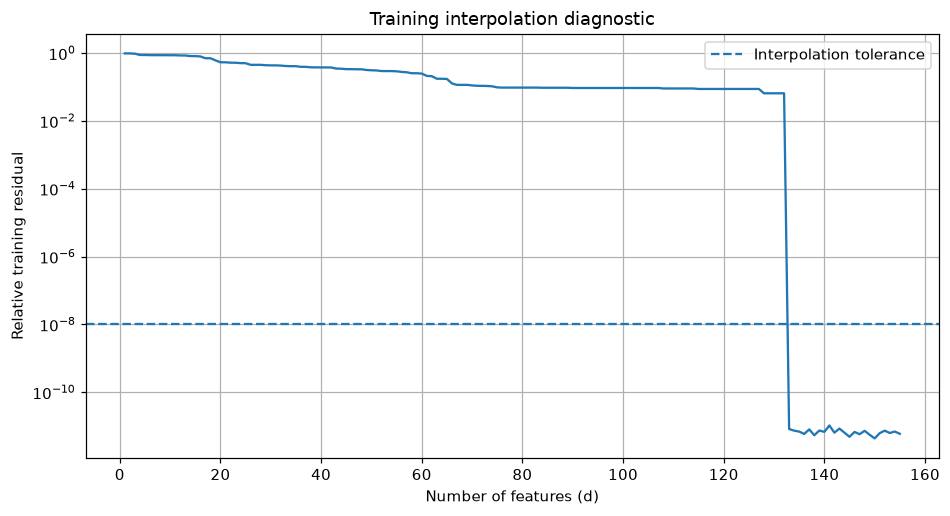

In [19]:
plt.figure(figsize=(10, 5))
plt.semilogy(D_VALUES_REAL, np.maximum(real_relative_residuals, 1e-16))
plt.axhline(INTERPOLATION_RTOL, linestyle="--", label="Interpolation tolerance")
plt.xlabel("Number of features (d)")
plt.ylabel("Relative training residual")
plt.title("Training interpolation diagnostic")
plt.legend()
plt.grid(True)
save_and_show("real_world_01")


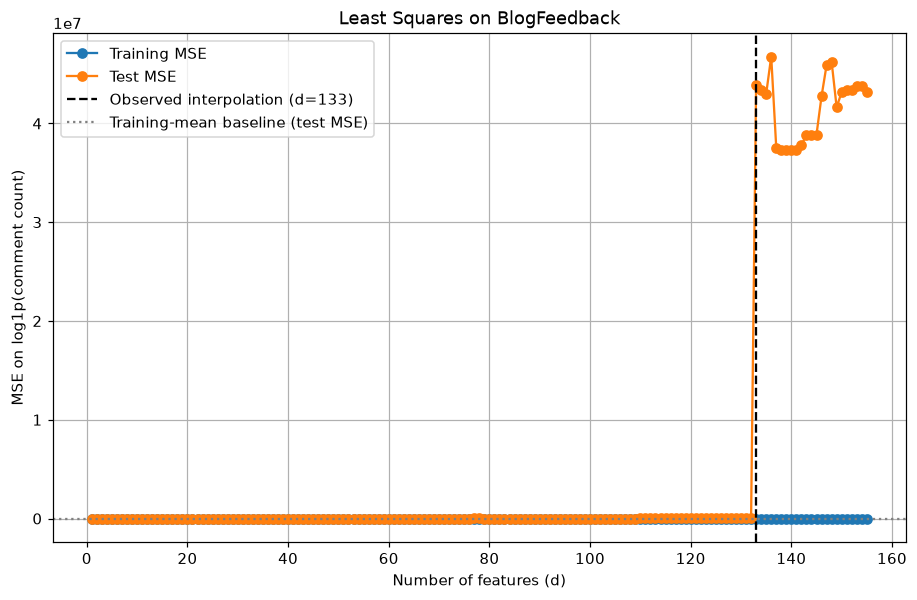

In [20]:
plt.figure(figsize=(10, 6))

plt.plot(
    D_VALUES_REAL,
    real_train_errors,
    marker="o",
    label="Training MSE"
)

plt.plot(
    D_VALUES_REAL,
    real_test_errors,
    marker="o",
    label="Test MSE"
)

if interpolation_dimension is not None:
    plt.axvline(interpolation_dimension, linestyle="--", color="black",
                label=f"Observed interpolation (d={interpolation_dimension})")

plt.xlabel("Number of features (d)")
plt.ylabel("MSE on log1p(comment count)")
plt.title("Least Squares on BlogFeedback")

plt.axhline(real_baseline_test_mse, color="grey", linestyle=":",
            label="Training-mean baseline (test MSE)")
plt.legend()
plt.grid(True)

save_and_show("real_world_02")

In [21]:
# Use exactly the same SVD cutoff as the fitted solver.
print(f"{'d':>5} {'rank':>6} {'train MSE':>12} {'test MSE':>14} {'relative residual':>18} {'min retained s':>16}")
for j, d in enumerate(D_VALUES_REAL):
    _, s, _, keep = svd_diagnostics(X_train_real_final[:, :d])
    smallest = s[keep][-1] if keep.any() else np.nan
    print(f"{d:5d} {int(keep.sum()):6d} {real_train_errors[j]:12.4g} "
          f"{real_test_errors[j]:14.4g} {real_relative_residuals[j]:18.4g} {smallest:16.4g}")


    d   rank    train MSE       test MSE  relative residual   min retained s
    1      1        1.119          1.087             0.9826            8.944
    2      2        1.116          1.089             0.9814            8.749
    3      3        1.073           1.11             0.9622            7.003
    4      4       0.9001          1.165             0.8814            6.014
    5      5       0.8997          1.372             0.8812            5.997
    6      6       0.8805          1.373             0.8717            5.343
    7      7       0.8782          1.322             0.8706            4.829
    8      8       0.8781          1.337             0.8705           0.8885
    9      9       0.8778          1.315             0.8704           0.8878
   10     10       0.8705          1.349             0.8668           0.8878
   11     11       0.8703          1.377             0.8667           0.8846
   12     12       0.8454          12.68             0.8542           0.8741

In [22]:
def fit_ridge_regression(X, y, alpha):
    """
    Ridge Regression from scratch.
    """

    d = X.shape[1]

    regularized_matrix = (
        X.T @ X
        + alpha * np.eye(d)
    )

    right_hand_side = X.T @ y

    w = np.linalg.solve(
        regularized_matrix,
        right_hand_side
    )

    return w

In [23]:
RIDGE_ALPHA_REAL = 1.0

real_ridge_train_errors = []
real_ridge_test_errors = []

for d in D_VALUES_REAL:

    X_train_d = X_train_real_final[:, :d]
    X_test_d = X_test_real_final[:, :d]

    w_ridge = fit_ridge_regression(
        X_train_d,
        y_train_real_centered,
        alpha=RIDGE_ALPHA_REAL
    )

    train_pred = X_train_d @ w_ridge
    test_pred = X_test_d @ w_ridge

    real_ridge_train_errors.append(
        mean_squared_error(
            y_train_real_centered,
            train_pred
        )
    )

    real_ridge_test_errors.append(
        mean_squared_error(
            y_test_real_centered,
            test_pred
        )
    )

real_ridge_train_errors = np.array(real_ridge_train_errors)
real_ridge_test_errors = np.array(real_ridge_test_errors)

print("Real-world Ridge experiment completed.")

Real-world Ridge experiment completed.


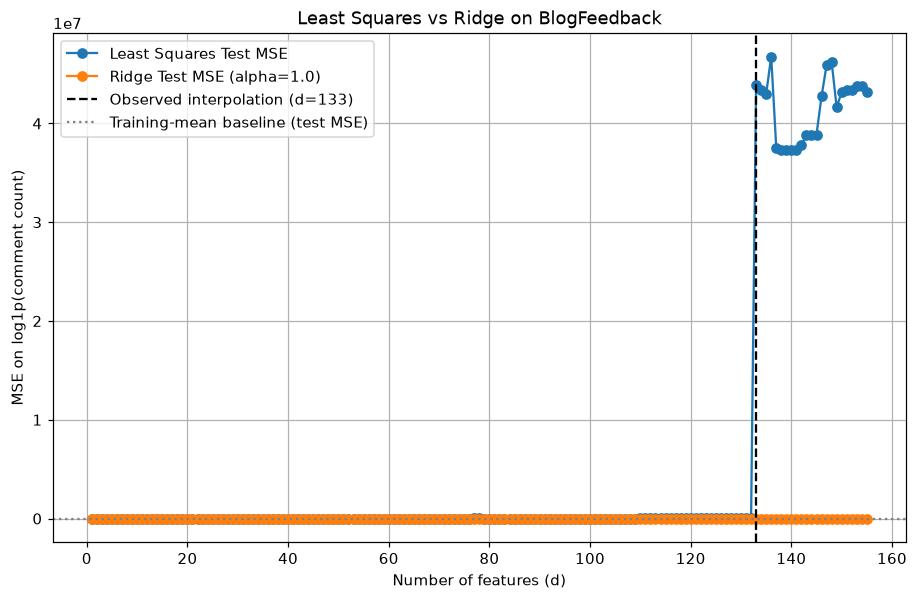

In [24]:
plt.figure(figsize=(10, 6))

plt.plot(
    D_VALUES_REAL,
    real_test_errors,
    marker="o",
    label="Least Squares Test MSE"
)

plt.plot(
    D_VALUES_REAL,
    real_ridge_test_errors,
    marker="o",
    label=f"Ridge Test MSE (alpha={RIDGE_ALPHA_REAL})"
)

if interpolation_dimension is not None:
    plt.axvline(interpolation_dimension, linestyle="--", color="black",
                label=f"Observed interpolation (d={interpolation_dimension})")

plt.xlabel("Number of features (d)")
plt.ylabel("MSE on log1p(comment count)")
plt.title("Least Squares vs Ridge on BlogFeedback")

plt.axhline(real_baseline_test_mse, color="grey", linestyle=":",
            label="Training-mean baseline (test MSE)")
plt.legend()
plt.grid(True)

save_and_show("real_world_03")

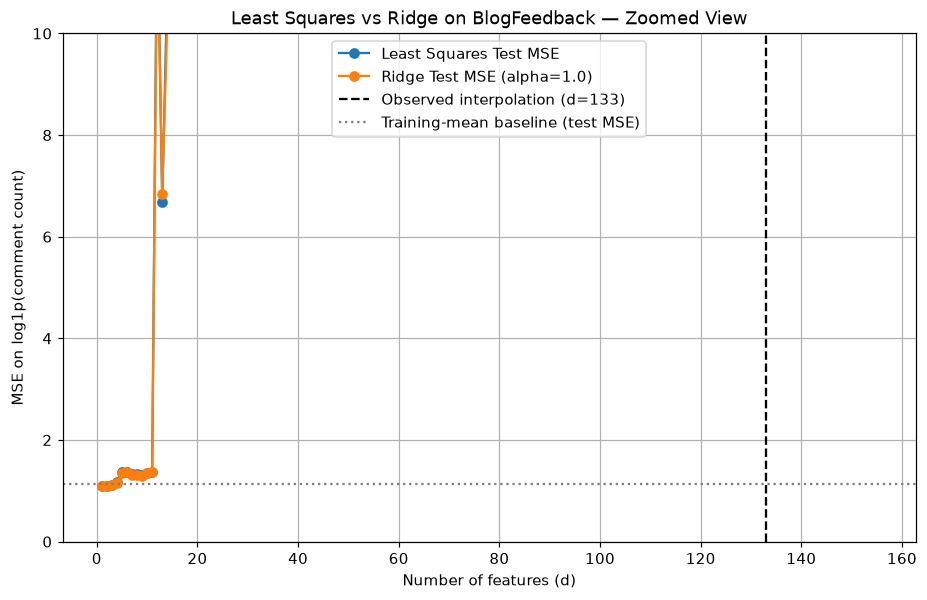

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(
    D_VALUES_REAL,
    real_test_errors,
    marker="o",
    label="Least Squares Test MSE"
)

plt.plot(
    D_VALUES_REAL,
    real_ridge_test_errors,
    marker="o",
    label=f"Ridge Test MSE (alpha={RIDGE_ALPHA_REAL})"
)

if interpolation_dimension is not None:
    plt.axvline(interpolation_dimension, linestyle="--", color="black",
                label=f"Observed interpolation (d={interpolation_dimension})")

plt.xlabel("Number of features (d)")
plt.ylabel("MSE on log1p(comment count)")
plt.title("Least Squares vs Ridge on BlogFeedback — Zoomed View")

plt.ylim(0, 10)

plt.axhline(real_baseline_test_mse, color="grey", linestyle=":",
            label="Training-mean baseline (test MSE)")
plt.legend()
plt.grid(True)

save_and_show("real_world_04")

In [26]:
D_VALUES_REPEAT_FULL = np.arange(1, D_MAX_REAL + 1)

def run_real_world_experiment(seed, alpha=1.0):

    local_rng = np.random.default_rng(seed)

    # 1. Random training subset
    indices = local_rng.choice(
        X_full_real.shape[0],
        size=N_TRAIN_REAL,
        replace=False
    )

    X_train_raw = X_full_real[indices]
    y_train_raw = y_full_real[indices]

    # 2. Log-transform target
    y_train_log = np.log1p(y_train_raw)

    # 3. Random feature ordering
    feature_order = local_rng.permutation(
        X_train_raw.shape[1]
    )

    X_train = X_train_raw[:, feature_order]
    X_test = X_test_real_full[:, feature_order]

    # 4. Standardize using training data only
    feature_mean = X_train.mean(axis=0)
    feature_std = X_train.std(axis=0)

    nonconstant = feature_std > 0

    X_train = X_train[:, nonconstant]
    X_test = X_test[:, nonconstant]

    feature_mean = feature_mean[nonconstant]
    feature_std = feature_std[nonconstant]

    X_train = (
        X_train - feature_mean
    ) / feature_std

    X_test = (
        X_test - feature_mean
    ) / feature_std

    # 5. Center target using training information only
    target_mean = y_train_log.mean()

    y_train = y_train_log - target_mean
    y_test = y_test_real_log - target_mean

    least_squares_errors = []
    ridge_errors = []
    train_errors = []
    fitted_ranks = []
    relative_residuals = []

    for d in D_VALUES_REPEAT_FULL:

        # If this particular subset has too few usable features
        if d > X_train.shape[1]:
            train_errors.append(np.nan)
            fitted_ranks.append(np.nan)
            relative_residuals.append(np.nan)
            least_squares_errors.append(np.nan)
            ridge_errors.append(np.nan)
            continue

        Xtr = X_train[:, :d]
        Xte = X_test[:, :d]

        # Least Squares
        w_ls = fit_min_norm_least_squares(
            Xtr,
            y_train
        )

        train_errors.append(mean_squared_error(y_train, Xtr @ w_ls))
        fitted_ranks.append(int(svd_diagnostics(Xtr)[3].sum()))
        relative_residuals.append(relative_training_residual(Xtr, y_train, w_ls))
        ls_pred = Xte @ w_ls

        least_squares_errors.append(
            mean_squared_error(
                y_test,
                ls_pred
            )
        )

        # Ridge
        w_ridge = fit_ridge_regression(
            Xtr,
            y_train,
            alpha=alpha
        )

        ridge_pred = Xte @ w_ridge

        ridge_errors.append(
            mean_squared_error(
                y_test,
                ridge_pred
            )
        )

    residuals = np.array(relative_residuals)
    hits = D_VALUES_REPEAT_FULL[residuals < INTERPOLATION_RTOL]
    return {
        "baseline_test": mean_squared_error(y_test, np.zeros_like(y_test)),
        "ls_test": np.array(least_squares_errors),
        "ridge_test": np.array(ridge_errors),
        "ls_train": np.array(train_errors),
        "rank": np.array(fitted_ranks),
        "relative_residual": residuals,
        "usable_dimensions": X_train.shape[1],
        "interpolation_dimension": int(hits[0]) if len(hits) else None,
    }


In [27]:
N_REAL_REPETITIONS = 20
real_repetition_results = [
    run_real_world_experiment(seed, alpha=1.0)
    for seed in range(N_REAL_REPETITIONS)
]
# Keep unsupported dimensions as NaN; never silently truncate a model.
all_real_ls = np.array([r["ls_test"] for r in real_repetition_results])
all_real_ridge = np.array([r["ridge_test"] for r in real_repetition_results])
all_real_train = np.array([r["ls_train"] for r in real_repetition_results])
all_real_ranks = np.array([r["rank"] for r in real_repetition_results])
all_real_residuals = np.array([r["relative_residual"] for r in real_repetition_results])
valid_counts = np.sum(np.isfinite(all_real_ls), axis=0)
# Compare repetitions on dimensions available in every run.
repeat_plot_mask = valid_counts == N_REAL_REPETITIONS
D_VALUES_REPEAT = D_VALUES_REPEAT_FULL[repeat_plot_mask]
all_real_ls = all_real_ls[:, repeat_plot_mask]
all_real_ridge = all_real_ridge[:, repeat_plot_mask]
mean_real_ls = all_real_ls.mean(axis=0)
mean_real_ridge = all_real_ridge.mean(axis=0)
median_real_ls = np.median(all_real_ls, axis=0)
median_real_ridge = np.median(all_real_ridge, axis=0)
for seed, result in enumerate(real_repetition_results):
    print(f"seed={seed:2d} usable={result['usable_dimensions']:3d} "
          f"first interpolation={result['interpolation_dimension']}")
print("Runs reaching interpolation:", sum(
    r["interpolation_dimension"] is not None for r in real_repetition_results
), "/", N_REAL_REPETITIONS)
print("Common plotting range:", D_VALUES_REPEAT[0], "to", D_VALUES_REPEAT[-1])

all_real_baseline = np.array([r["baseline_test"] for r in real_repetition_results])
mean_real_baseline = all_real_baseline.mean()
median_real_baseline = np.median(all_real_baseline)
print("Mean baseline test MSE:", mean_real_baseline)
print("Median baseline test MSE:", median_real_baseline)


seed= 0 usable=162 first interpolation=91
seed= 1 usable=161 first interpolation=80
seed= 2 usable=164 first interpolation=84
seed= 3 usable=168 first interpolation=82
seed= 4 usable=157 first interpolation=80
seed= 5 usable=157 first interpolation=90
seed= 6 usable=162 first interpolation=81
seed= 7 usable=160 first interpolation=93
seed= 8 usable=157 first interpolation=86
seed= 9 usable=172 first interpolation=89
seed=10 usable=161 first interpolation=82
seed=11 usable=149 first interpolation=82
seed=12 usable=154 first interpolation=85
seed=13 usable=156 first interpolation=82
seed=14 usable=155 first interpolation=89
seed=15 usable=150 first interpolation=81
seed=16 usable=154 first interpolation=83
seed=17 usable=160 first interpolation=91
seed=18 usable=158 first interpolation=84
seed=19 usable=158 first interpolation=81
Runs reaching interpolation: 20 / 20
Common plotting range: 1 to 149
Mean baseline test MSE: 1.1561776471195242
Median baseline test MSE: 1.1472319562831066


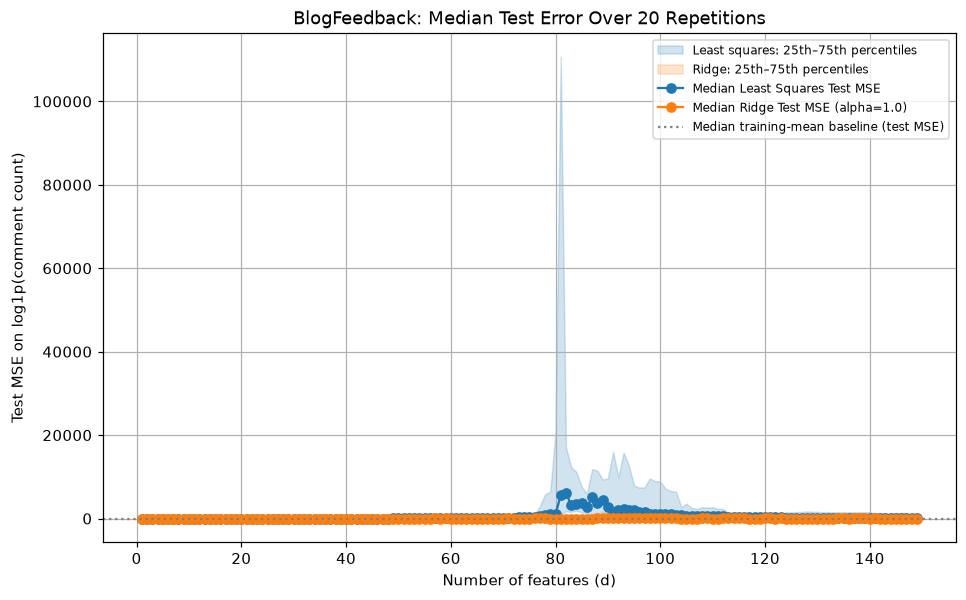

In [28]:
ls_q25, ls_q75 = np.percentile(all_real_ls, [25, 75], axis=0)
ridge_q25, ridge_q75 = np.percentile(all_real_ridge, [25, 75], axis=0)
plt.figure(figsize=(10, 6))
plt.fill_between(D_VALUES_REPEAT, ls_q25, ls_q75, alpha=0.2, color="C0",
                 label="Least squares: 25th–75th percentiles")
plt.fill_between(D_VALUES_REPEAT, ridge_q25, ridge_q75, alpha=0.2, color="C1",
                 label="Ridge: 25th–75th percentiles")

plt.plot(
    D_VALUES_REPEAT,
    median_real_ls,
    marker="o",
    label="Median Least Squares Test MSE"
)

plt.plot(
    D_VALUES_REPEAT,
    median_real_ridge,
    marker="o",
    label="Median Ridge Test MSE (alpha=1.0)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Test MSE on log1p(comment count)")

plt.title(
    f"BlogFeedback: Median Test Error Over {N_REAL_REPETITIONS} Repetitions"
)

plt.axhline(median_real_baseline, color="grey", linestyle=":",
            label="Median training-mean baseline (test MSE)")
plt.legend(fontsize=8)
plt.grid(True)

save_and_show("real_world_05")

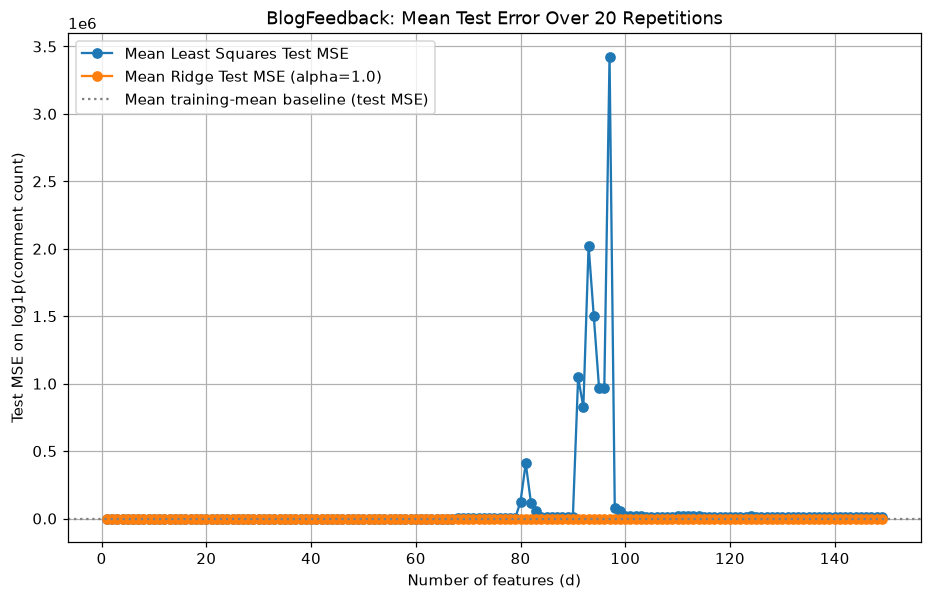

In [29]:
plt.figure(figsize=(10, 6))

plt.plot(
    D_VALUES_REPEAT,
    mean_real_ls,
    marker="o",
    label="Mean Least Squares Test MSE"
)

plt.plot(
    D_VALUES_REPEAT,
    mean_real_ridge,
    marker="o",
    label="Mean Ridge Test MSE (alpha=1.0)"
)

plt.xlabel("Number of features (d)")
plt.ylabel("Test MSE on log1p(comment count)")

plt.title(
    f"BlogFeedback: Mean Test Error Over {N_REAL_REPETITIONS} Repetitions"
)

plt.axhline(mean_real_baseline, color="grey", linestyle=":",
            label="Mean training-mean baseline (test MSE)")
plt.legend()
plt.grid(True)

save_and_show("real_world_06")

In [30]:
def run_noise_experiment(
    noise_std,
    n_train=150,
    n_test=1000,
    d_max=400,
    d_values=None,
    seed=42
):
    """
    Run the synthetic double-descent experiment
    for a given noise level.
    """

    if d_values is None:
        d_values = np.array([
            10, 20, 40, 60, 80, 100, 120, 130, 140,
            145, 148, 149, 150, 151, 152, 155, 160,
            170, 180, 200, 250, 300, 350, 400
        ])

    local_rng = np.random.default_rng(seed)

    # Generate features
    X_train = local_rng.normal(
        size=(n_train, d_max)
    )

    X_test = local_rng.normal(
        size=(n_test, d_max)
    )

    # Generate true coefficients
    feature_index = np.arange(d_max)

    signs = local_rng.choice(
        [-1.0, 1.0],
        size=d_max
    )

    beta = signs * np.exp(
        -0.02 * feature_index
    )

    beta = beta / np.linalg.norm(beta)

    # Generate labels
    y_train_local = (
        X_train @ beta
        + local_rng.normal(
            scale=noise_std,
            size=n_train
        )
    )

    y_test_local = (
        X_test @ beta
        + local_rng.normal(
            scale=noise_std,
            size=n_test
        )
    )

    test_errors_local = []

    for d in d_values:

        Xtr = X_train[:, :d]
        Xte = X_test[:, :d]

        w_hat = fit_min_norm_least_squares(
            Xtr,
            y_train_local
        )

        predictions = Xte @ w_hat

        test_errors_local.append(
            mean_squared_error(
                y_test_local,
                predictions
            )
        )

    return np.array(test_errors_local)

In [31]:
NOISE_LEVELS = [0.1, 0.5, 1.0]

noise_results = {}

for noise in NOISE_LEVELS:
    noise_results[noise] = run_noise_experiment(
        noise_std=noise,
        seed=42
    )

print("Noise experiments completed.")

Noise experiments completed.


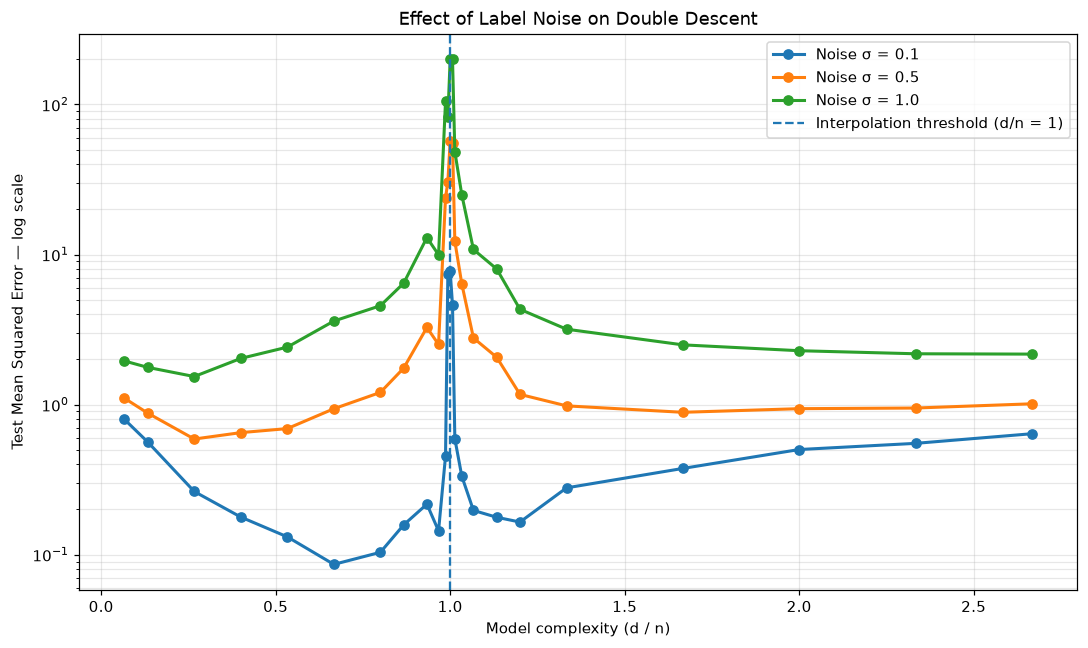

In [32]:
# Better visualization: model complexity as d/n + logarithmic y-axis

D_VALUES_NOISE = np.array([
    10, 20, 40, 60, 80, 100, 120, 130, 140,
    145, 148, 149, 150, 151, 152, 155, 160,
    170, 180, 200, 250, 300, 350, 400
])

N_TRAIN_NOISE = 150

complexity_ratio = D_VALUES_NOISE / N_TRAIN_NOISE

plt.figure(figsize=(10, 6))

for noise in NOISE_LEVELS:
    plt.plot(
        complexity_ratio,
        noise_results[noise],
        marker="o",
        linewidth=2,
        label=f"Noise σ = {noise}"
    )

# Interpolation threshold: d / n = 1
plt.axvline(
    x=1.0,
    linestyle="--",
    label="Interpolation threshold (d/n = 1)"
)

# Logarithmic scale
plt.yscale("log")

plt.xlabel("Model complexity (d / n)")
plt.ylabel("Test Mean Squared Error — log scale")

plt.title("Effect of Label Noise on Double Descent")

plt.legend()
plt.grid(
    True,
    which="both",
    alpha=0.3
)

plt.tight_layout()
save_and_show("real_world_07")

## Variability and scale

Shaded bands show the middle 50% of errors across 20 random training subsets and feature orderings. These are descriptive interquartile ranges, not confidence intervals. All repetitions use the same fixed temporal test set; they do not measure uncertainty across independent test samples. Repeated curves use only dimensions available in every run. The baseline is fitted separately from each run's training log-targets.


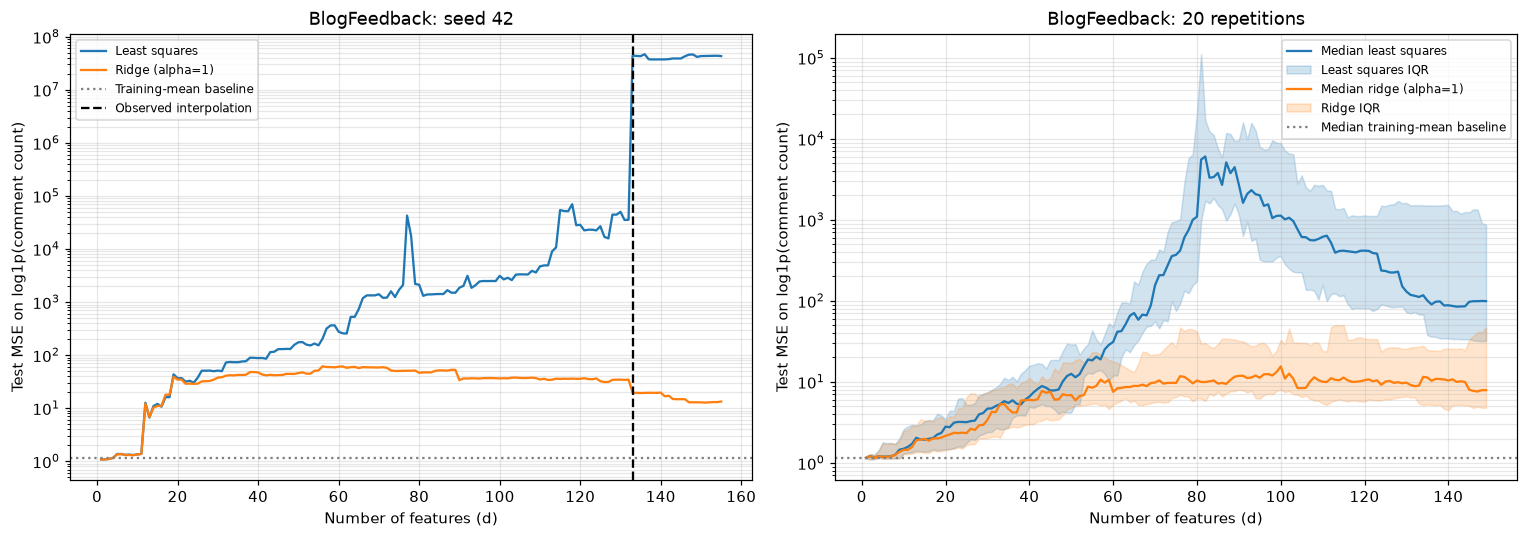

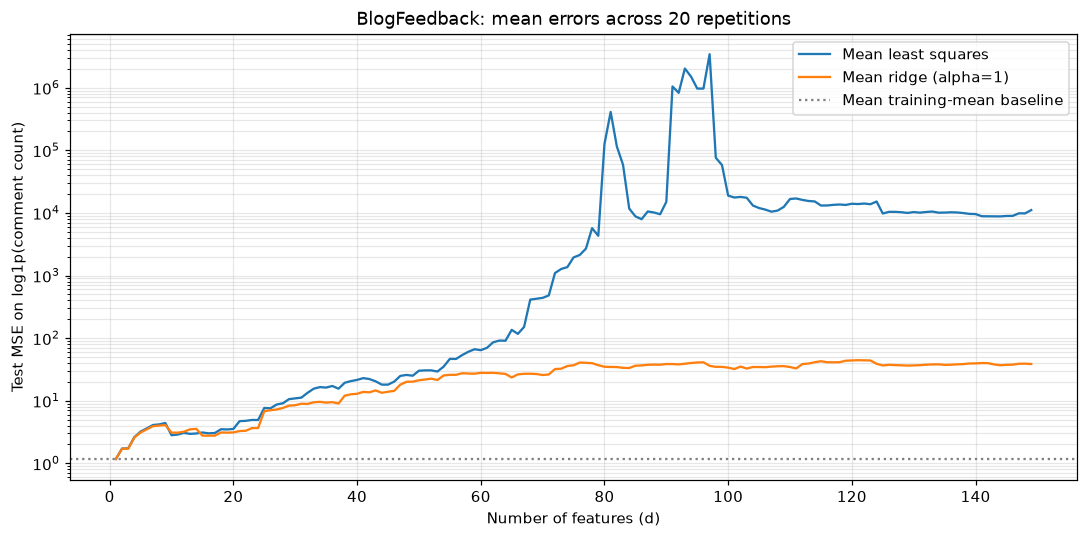

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(D_VALUES_REAL, real_test_errors, label="Least squares")
ax.plot(D_VALUES_REAL, real_ridge_test_errors, label="Ridge (alpha=1)")
ax.axhline(real_baseline_test_mse, color="grey", linestyle=":", label="Training-mean baseline")
if interpolation_dimension is not None:
    ax.axvline(interpolation_dimension, color="black", linestyle="--", label="Observed interpolation")
ax.set_title("BlogFeedback: seed 42")
ax = axes[1]
ax.plot(D_VALUES_REPEAT, median_real_ls, color="C0", label="Median least squares")
ax.fill_between(D_VALUES_REPEAT, ls_q25, ls_q75, color="C0", alpha=0.2, label="Least squares IQR")
ax.plot(D_VALUES_REPEAT, median_real_ridge, color="C1", label="Median ridge (alpha=1)")
ax.fill_between(D_VALUES_REPEAT, ridge_q25, ridge_q75, color="C1", alpha=0.2, label="Ridge IQR")
ax.axhline(median_real_baseline, color="grey", linestyle=":", label="Median training-mean baseline")
ax.set_title("BlogFeedback: 20 repetitions")
for ax in axes:
    ax.set_yscale("log")
    ax.set_xlabel("Number of features (d)")
    ax.set_ylabel("Test MSE on log1p(comment count)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
save_and_show("real_world_08")

# Mean view retained separately: extreme runs can dominate this statistic.
plt.figure(figsize=(10, 5))
plt.plot(D_VALUES_REPEAT, mean_real_ls, label="Mean least squares")
plt.plot(D_VALUES_REPEAT, mean_real_ridge, label="Mean ridge (alpha=1)")
plt.axhline(mean_real_baseline, color="grey", linestyle=":", label="Mean training-mean baseline")
plt.yscale("log")
plt.xlabel("Number of features (d)")
plt.ylabel("Test MSE on log1p(comment count)")
plt.title("BlogFeedback: mean errors across 20 repetitions")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
save_and_show("real_world_09")


In [34]:
# Descriptive diagnostics, not test-based hyperparameter selection.
peak = int(np.argmax(median_real_ls))
final = -1
print("Median LS peak: d =", D_VALUES_REPEAT[peak], "MSE =", median_real_ls[peak])
print("Final common dimension:", D_VALUES_REPEAT[final])
print("Final median LS / ridge / baseline:", median_real_ls[final], median_real_ridge[final], median_real_baseline)
print("Final ridge wins versus its paired baseline:", int(np.sum(all_real_ridge[:, final] < all_real_baseline)), "/", N_REAL_REPETITIONS)
print("Single-run final LS / ridge / baseline:", real_test_errors[-1], real_ridge_test_errors[-1], real_baseline_test_mse)
print("First / final median LS MSE:", median_real_ls[0], median_real_ls[-1])


Median LS peak: d = 82 MSE = 6063.2085579452105
Final common dimension: 149
Final median LS / ridge / baseline: 99.27674426806817 7.903449085806031 1.1472319562831066
Final ridge wins versus its paired baseline: 0 / 20
Single-run final LS / ridge / baseline: 43141024.94722783 13.368376605451974 1.13571047255158
First / final median LS MSE: 1.1519423195729317 99.27674426806817


## Interpretation of the real-world results

Interpolation is verified from training residuals in all 20 repeated runs, at dimensions 80–93. The seed-42 illustration reaches interpolation at d = 133. These differences reflect the sampled observations, feature ordering, and matrix conditioning; an interpolation threshold must not simply be assumed at d = n.

The repeated median least-squares curve has an instability peak of about 6,063.21 at d = 82, followed by a decline to 99.28 at the final common dimension, d = 149. This is evidence of a peak and subsequent descent around the repeated runs' interpolation region. It is not a clean reproduction of the full classical-plus-modern double-descent curve: the low-dimensional errors are already much smaller, and the curve lacks a clear initial descending segment. The seed-42 illustration is particularly unstable, with final least-squares MSE about 43.14 million; it does not show a convincing second descent. It is retained to expose variability rather than replaced by a favorable seed.

Ridge with alpha = 1 controls much of the least-squares instability, but does not deliver good predictive performance at the final common dimension. Median ridge MSE there is 7.90 versus 1.15 for the training-mean baseline, and ridge loses to its paired baseline in all 20 runs at that dimension. This comparison is specific to d = 149 and does not assert that ridge loses at every dimension. A large improvement over unstable least squares is therefore insufficient evidence of useful prediction.

The IQR shows substantial sensitivity to training subsets and feature ordering. Means can be dominated by a few extreme runs. All errors are on the log1p(comment count) scale. The fixed test set contains 214 observations from a single later date; repeated training runs do not remove temporal distribution differences or quantify uncertainty across test dates. The real-world result should be presented as an instability and regularization case with mixed evidence for double descent, alongside the clearer synthetic demonstration. Neither dimensions nor regularization strengths are selected from these test curves.


## Ridge strength and five-fold training-only cross-validation

This separate extension keeps all original alpha=1 results. Its x-axis counts raw columns in the predetermined random feature order, before fold-specific constant-column removal. It therefore differs from the earlier effective-feature axis. Every inner fold fits its own scaler, constant-column mask, and target mean using only its fitting rows. Alpha is selected separately at each fixed dimension using only validation errors inside the 80-row training subset. The official test file is used only for final evaluation.


Final raw dimension: 280
alpha=0.01: final median test MSE=45.205561; wins versus baseline=0/20
alpha=0.1: final median test MSE=20.184873; wins versus baseline=0/20
alpha=1: final median test MSE=9.400267; wins versus baseline=0/20
alpha=10: final median test MSE=5.484366; wins versus baseline=0/20
alpha=100: final median test MSE=2.488159; wins versus baseline=1/20
CV final median test MSE: 3.5568421746272225
Baseline median test MSE: 1.1472319562831066
CV wins versus paired baseline: 1 / 20
Final selected alphas: [100.0, 100.0, 100.0, 100.0, 100.0, 10.0, 100.0, 100.0, 100.0, 100.0, 0.01, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0]


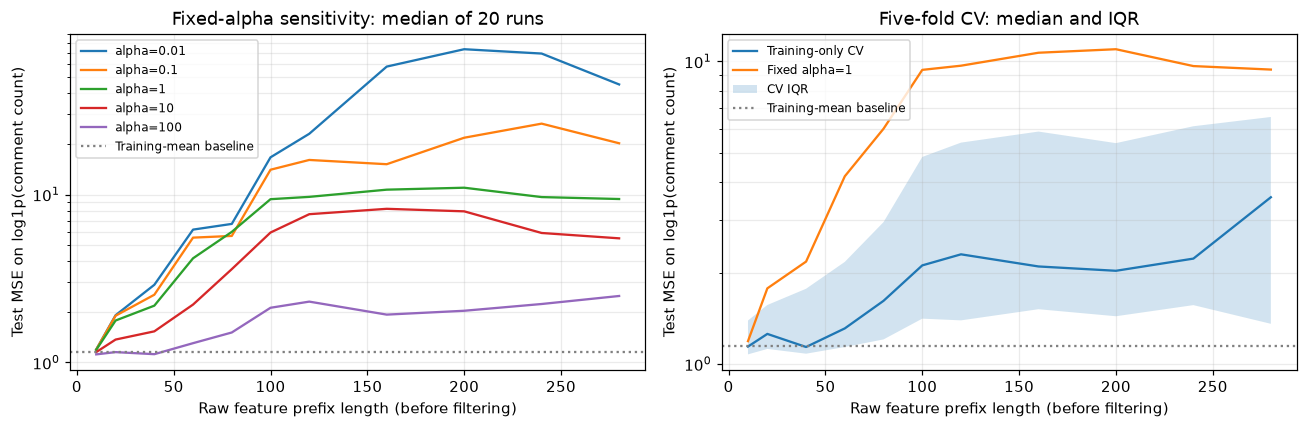

In [35]:
import sys
sys.path.insert(0, str(Path("../src").resolve()))
from extensions import run_real_ridge_extension

REAL_ALPHAS = np.array([0.01, 0.1, 1.0, 10.0, 100.0])
CV_DIMENSIONS = np.array([10, 20, 40, 60, 80, 100, 120, 160, 200, 240, 280])
ridge_cv_runs = [run_real_ridge_extension(
    X_full_real, y_full_real, X_test_real_full, y_test_real, seed,
    CV_DIMENSIONS, REAL_ALPHAS, N_TRAIN_REAL, k=5
) for seed in range(N_REAL_REPETITIONS)]
# Seed 42 is retained as an illustration, not selected using test performance.
ridge_cv_seed42 = run_real_ridge_extension(
    X_full_real, y_full_real, X_test_real_full, y_test_real, RANDOM_SEED,
    CV_DIMENSIONS, REAL_ALPHAS, N_TRAIN_REAL, k=5)
# At all 280 raw columns this matches the existing final alpha=1 fit.
np.testing.assert_allclose(ridge_cv_seed42["test_by_alpha"][-1][2],
                           real_ridge_test_errors[-1], rtol=1e-8)
cv_array = np.array([run["cv_test"] for run in ridge_cv_runs])
alpha_array = np.array([run["test_by_alpha"] for run in ridge_cv_runs])
cv_baselines = np.array([run["baseline_test"] for run in ridge_cv_runs])
ridge_cv_results = {"dimensions": CV_DIMENSIONS, "alphas": REAL_ALPHAS,
                    "folds": 5, "runs": ridge_cv_runs, "seed42": ridge_cv_seed42}
print("Final raw dimension:", CV_DIMENSIONS[-1])
for j, alpha in enumerate(REAL_ALPHAS):
    print(f"alpha={alpha:g}: final median test MSE={np.median(alpha_array[:, -1, j]):.6f}; "
          f"wins versus baseline={np.sum(alpha_array[:, -1, j] < cv_baselines)}/{N_REAL_REPETITIONS}")
print("CV final median test MSE:", np.median(cv_array[:, -1]))
print("Baseline median test MSE:", np.median(cv_baselines))
print("CV wins versus paired baseline:", np.sum(cv_array[:, -1] < cv_baselines), "/", N_REAL_REPETITIONS)
print("Final selected alphas:", [run["selected_alpha"][-1] for run in ridge_cv_runs])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j, alpha in enumerate(REAL_ALPHAS):
    axes[0].plot(CV_DIMENSIONS, np.median(alpha_array[:, :, j], axis=0), label=f"alpha={alpha:g}")
axes[0].set_title("Fixed-alpha sensitivity: median of 20 runs")
axes[1].plot(CV_DIMENSIONS, np.median(cv_array, axis=0), label="Training-only CV")
axes[1].plot(CV_DIMENSIONS, np.median(alpha_array[:, :, 2], axis=0), label="Fixed alpha=1")
lo, hi = np.percentile(cv_array, [25, 75], axis=0)
axes[1].fill_between(CV_DIMENSIONS, lo, hi, alpha=0.2, label="CV IQR")
axes[1].set_title("Five-fold CV: median and IQR")
for ax in axes:
    ax.axhline(np.median(cv_baselines), color="grey", linestyle=":", label="Training-mean baseline")
    ax.set_xlabel("Raw feature prefix length (before filtering)")
    ax.set_ylabel("Test MSE on log1p(comment count)")
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
save_and_show("real_ridge_cv")


At all 280 raw columns, training-only CV has median test MSE about 3.557, compared with 1.147 for the baseline, and wins in 1/20 paired runs. Stronger fixed regularization improves the sensitivity curves but does not establish reliable out-of-sample performance. These endpoints differ from the earlier common effective dimension of 149; the original alpha=1 result remains unchanged.